# Data Mining Lab 2
## Өгөгдлийн шинж чанар: Тайлбарлалт, Дүрслэл ба Төсөөлөл
**Dataset:** StudentsPerformance.csv

**Зорилго:**  
Энэхүү лабораторийн ажлыг дуусгасны дараа оюутан:
- Өгөгдлийн объект, аттрибутын тухай ойлголтыг бодит dataset дээр ашиглаж сурна  
- Статистик тайлбарлалтын аргуудыг (төв хандлага, хэлбэлзэл, тархалтын хэлбэр) тооцоолж чадна  
- Өгөгдлийг график аргаар зөв дүрслэнэ  
- Өгөгдлийн объектуудын хоорондын төсөө (similarity) ба ялгааг (dissimilarity) хэмжинэ  
- Нормализацийн аргуудыг (Min-Max, Z-score) ойлгож, хэрэглэнэ  



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)


## 0) Dataset унших

**StudentsPerformance.csv** файлыг ашиглана.



In [2]:
df = pd.read_csv("StudentsPerformance.csv")
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 1) Өгөгдлийн объект ба аттрибут (Data Object & Attribute)

- Dataset дахь **мөр бүр** нэг өгөгдлийн объект (нэг оюутан) юм: x=(a₁, a₂, …, aₙ)  
- Dataset дахь **багана бүр** нэг аттрибут (feature)  

### 1.1 Dataset-ийн бүтэц
- Хэдэн объект (мөр), хэдэн аттрибут (багана) вэ?  
- Аль аттрибут numeric, аль нь categorical вэ?



In [3]:
print("Shape (objects, attributes):", df.shape)
print("Attributes:", list(df.columns))
df.dtypes


Shape (objects, attributes): (1000, 8)
Attributes: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

### 1.2 Missing болон duplicate шалгах

- Аль аттрибутад missing value байна вэ?  
- Давхардсан объект (мөр) байгаа эсэх?



In [4]:
# Missing values
df.isna().sum()


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [5]:
# Duplicate rows
df.duplicated().sum()


np.int64(0)

### 1.3 Numeric ба Categorical аттрибутууд



In [6]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

print("Numeric columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))


Numeric columns: ['math score', 'reading score', 'writing score']
Categorical columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


### TASK A: Аттрибутын хэмжээсийн түвшин (Measurement Level)

Лекцийн дагуу (**Nominal, Ordinal, Interval, Ratio**) доорх аттрибут бүрийг ангилж, шалтгаанаа бичнэ үү:

| Аттрибут | Төрөл (Nominal/Ordinal/Interval/Ratio) | Шалтгаан |
|---|---|---|
| gender | Nominal | Тодорхой дараалал гэх зүйл тогтоож болохгүй  |
| race/ethnicity | Nominal | Тодорхой дараалал гэх зүйл тогтоож болохгүй |
| parental level of education | Ordinal | Боловсролын зэрэг нь дараалалтай|
| lunch | Ordinal | Стандарт хоолтой байх нь reduced буюу багасгасан хоолны багцтай байхаас илүү тул дараалалтай гэж үзэж болно |
| test preparation course | Ordinal | Өмнө нь бэлдсэн байх нь бэлдээгүй байхаас илүү тул дараалалтай гэж үзэж болно |
| math score | Ratio | Санамжид тайлбарласан байна |
| reading score | Ordianal | 0 цэг байхгүй тоон утга |
| writing score | Ordinal | 0 цэг байхгүй тоон утга |

**Санамж:** score-ууд нь 0 цэгтэй (0 оноо = мэдлэггүй гэсэн үг биш ч бодит тоон утга) тул ихэвчлэн ratio гэж авч үздэг, харин `parental level of education` дараалалтай тул ordinal.



In [ ]:
# энд өөрийн ангиллаа код/тайлбар хэлбэрээр баталгаажуулж болно


## 2) Статистик тайлбарлалт (Statistical Description)

### 2.1 Ерөнхий статистик



In [7]:
df.describe()


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### 2.2 Төв хандлага: Mean, Median, Mode

- **Mean** — бүх утгыг ашигладаг ч outlier-д мэдрэмтгий  
- **Median** — эрэмбэлсэн дундах утга, outlier-д тэсвэртэй  
- **Mode** — хамгийн олон давтагдсан утга



In [8]:
for col in num_cols:
    print(f"{col:15s} mean={df[col].mean():.2f}  median={df[col].median():.2f}  mode={df[col].mode()[0]}")


math score      mean=66.09  median=66.00  mode=65
reading score   mean=69.17  median=70.00  mode=72
writing score   mean=68.05  median=69.00  mode=74


### 2.3 Хэлбэлзэл: Variance, Std



In [10]:
for col in num_cols:
    print(f"{col:15s} variance={df[col].var():.2f}  std={df[col].std():.2f}")

math score      variance=229.92  std=15.16
reading score   variance=213.17  std=14.60
writing score   variance=230.91  std=15.20


### 2.4 Тархалтын хэлбэр (Distribution Shape)

Лекц ёсоор:
- Symmetric: Mean ≈ Median ≈ Mode  
- Left-skewed: Mean < Median < Mode  
- Right-skewed: Mode < Median < Mean

Доорх код Mean ба Median-ийг харьцуулж, тархалтын хэлбэрийг тодорхойлно.



In [11]:
for col in num_cols:
    m, med = df[col].mean(), df[col].median()
    if abs(m - med) < 0.5:
        shape = "Symmetric"
    elif m < med:
        shape = "Left-skewed"
    else:
        shape = "Right-skewed"
    print(f"{col:15s} mean={m:.2f} median={med:.2f} -> {shape}")


math score      mean=66.09 median=66.00 -> Symmetric
reading score   mean=69.17 median=70.00 -> Left-skewed
writing score   mean=68.05 median=69.00 -> Left-skewed


## 3) Graphик дүрслэл (Visualization)

Лекцэд дурдсанчлан аттрибутын төрлөөс хамааран график сонгоно:

| Өгөгдөл | График |
|---|---|
| Categorical | Bar, Pie |
| Numerical | Histogram, Boxplot |
| Relationship | Scatter |



### 3.1 Bar chart – Categorical аттрибут (race/ethnicity)


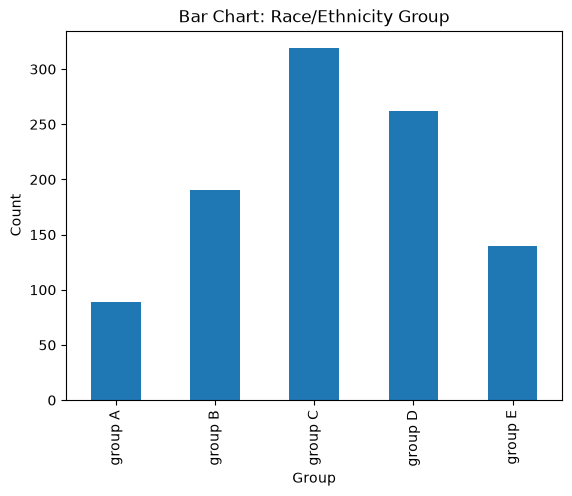

In [12]:
plt.figure()
df['race/ethnicity'].value_counts().sort_index().plot(kind='bar')
plt.title("Bar Chart: Race/Ethnicity Group")
plt.xlabel("Group")
plt.ylabel("Count")
plt.show()

### 3.2 Histogram – Reading score


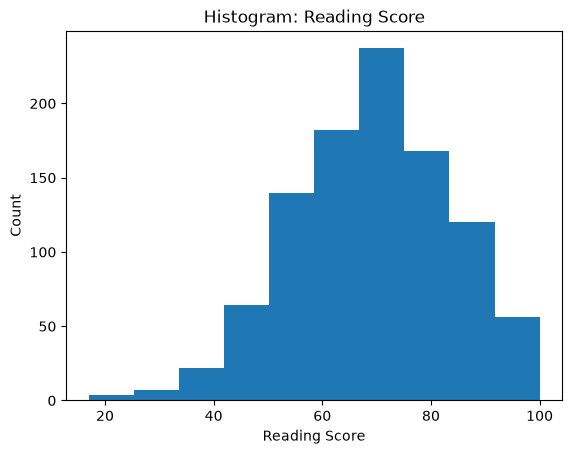

In [13]:
plt.figure()
plt.hist(df['reading score'], bins=10)
plt.title("Histogram: Reading Score")
plt.xlabel("Reading Score")
plt.ylabel("Count")
plt.show()


### 3.3 Boxplot – Test preparation course vs Writing score


<Figure size 640x480 with 0 Axes>

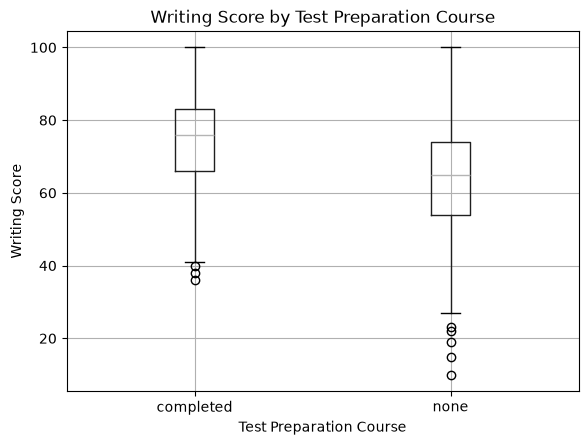

In [14]:
plt.figure()
df.boxplot(column='writing score', by='test preparation course')
plt.title("Writing Score by Test Preparation Course")
plt.suptitle("")
plt.xlabel("Test Preparation Course")
plt.ylabel("Writing Score")
plt.show()


### 3.4 Scatter – Reading vs Writing score


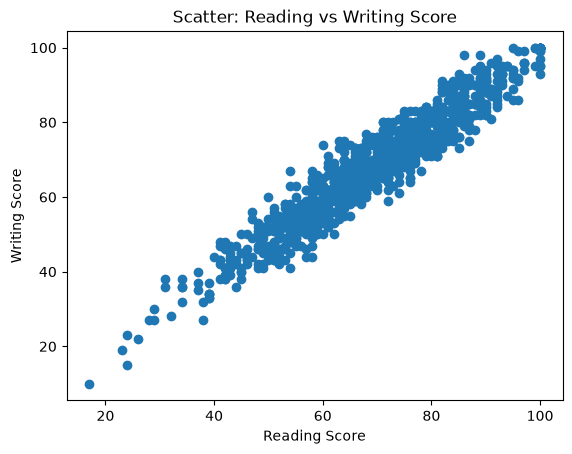

In [15]:
plt.figure()
plt.scatter(df['reading score'], df['writing score'])
plt.title("Scatter: Reading vs Writing Score")
plt.xlabel("Reading Score")
plt.ylabel("Writing Score")
plt.show()


## 4) Төсөө ба ялгаа (Similarity & Dissimilarity)

- **Euclidean distance:** d(x,y) = sqrt(Σ(xᵢ - yᵢ)²)  
- **Manhattan distance:** d(x,y) = Σ|xᵢ - yᵢ|  

Доорх жишээнд эхний 3 оюутны (`math score`, `reading score`, `writing score`) утгуудыг ашиглан хос бүрийн зайг тооцооно.



In [16]:
from itertools import combinations

sample = df.loc[0:2, ['math score', 'reading score', 'writing score']]
sample.index = ['A', 'B', 'C']
sample


,math score,reading score,writing score
A,72,72,74
B,69,90,88
C,90,95,93


In [17]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan(a, b):
    return np.sum(np.abs(a - b))

for i, j in combinations(sample.index, 2):
    a, b = sample.loc[i].values, sample.loc[j].values
    print(f"{i}-{j}:  Euclidean={euclidean(a, b):.2f}   Manhattan={manhattan(a, b):.2f}")


A-B:  Euclidean=23.00   Manhattan=35.00
A-C:  Euclidean=34.84   Manhattan=60.00
B-C:  Euclidean=22.16   Manhattan=31.00


### TASK B: Хамгийн төстэй оюутнууд

1. Дээрх гурван оюутны аль хос нь хамгийн бага Euclidean distance-той, өөрөөр хэлбэл хамгийн **төстэй** вэ?  
2. Manhattan distance-аар бодоход хариулт өөрчлөгдөж байна уу?  
3. Өөрийн сонгосон 3 өөр оюутнаар дахин тооцоолж, дүгнэлт хий.



In [19]:
# code
# В болон С оюутнууд хамгийн төстэй байна.
# Manhattan зайгаар ч мөн адил В болон С оюутнууд хамгийн төстэй байна.

sample2 = df.loc[2:4, ['math score', 'reading score', 'writing score']]
sample2.index = ['D', 'E', 'F']
sample2

,math score,reading score,writing score
D,90,95,93
E,47,57,44
F,76,78,75


In [20]:
for i, j in combinations(sample2.index, 2):
    a, b = sample2.loc[i].values, sample2.loc[j].values
    print(f"{i}-{j}:  Euclidean={euclidean(a, b):.2f}   Manhattan={manhattan(a, b):.2f}")

D-E:  Euclidean=75.46   Manhattan=130.00
D-F:  Euclidean=28.44   Manhattan=49.00
E-F:  Euclidean=47.36   Manhattan=81.00


Өөр 3 оюутан дээр авч үзэхэд мөн manhattan distance болон euclidean distance-үүд нь төстэй оюутнуудын хосод мөн ижил бага утга авч байна. Төс бага оюутнуудын хувьд харин ижил их утгатай байна. Хоёр төсөө шалгах томьёог утгуудаар нь эрэмбэлж үзвэл яг харгалзана гэсэн үг. Тиймээс дээрх хоёр томьёо нь өөр аргаар төсөөг тооцдог боловч гүндээ бараг адилхан гэж дүгнэж болохоор байна. Эцсийн эцэст нэг арга нь хоорондын зөрүүг модуль авч нэмж байгаа нөгөө арга нь зөрүүнүүдийн квадрат утгуудыг нэмж язгуур авч байгаа тул гүндээ яг л ижил зөрүүнүүдийн нийлбэрийг нь олж байна.

## 5) Нормализаци (Normalization)

Яагаад хэрэгтэй вэ? Өөр өөр масштабтай аттрибутууд distance тооцооллыг гуйвуулахаас сэргийлнэ.

- **Min-Max normalization:** x' = (x - min) / (max - min)  
- **Z-score normalization:** x' = (x - mean) / std



In [21]:
scores = df[['math score', 'reading score', 'writing score']]

minmax = (scores - scores.min()) / (scores.max() - scores.min())
zscore = (scores - scores.mean()) / scores.std()

print("Min-Max normalized (эхний 5):")
display(minmax.head())
print("\nZ-score normalized (эхний 5):")
display(zscore.head())


Min-Max normalized (эхний 5):


,math score,reading score,writing score
0,0.72,0.662651,0.711111
1,0.69,0.879518,0.866667
2,0.90,0.939759,0.922222
3,0.47,0.481928,0.377778
4,0.76,0.734940,0.722222



Z-score normalized (эхний 5):


,math score,reading score,writing score
0,0.389828,0.193902,0.391296
1,0.191979,1.426762,1.312612
2,1.576922,1.769223,1.641653
3,-1.258913,-0.833482,-1.582952
4,0.653627,0.604855,0.457104


### TASK C: Нормализацийн нөлөө

1. Min-Max normalize хийсэн эхний 3 оюутны хооронд Euclidean distance-ийг дахин тооцоол.  
2. Normalize хийхээс өмнөх distance-тай харьцуулж, ялгааг тайлбарла (үгээр).  
3. Аль тохиолдолд normalization хийх нь **зайлшгүй шаардлагатай** вэ? (жишээ өг)



In [22]:
# code
sample3 = minmax.loc[0:2]
sample3.index = ['A', 'B', 'C']
sample3

,math score,reading score,writing score
A,0.72,0.662651,0.711111
B,0.69,0.879518,0.866667
C,0.90,0.939759,0.922222


In [24]:
# Normalization-ийн өмнөх Euclidean distance
# A-B:  Euclidean=23.00   
# A-C:  Euclidean=34.84   
# B-C:  Euclidean=22.16

for i, j in combinations(sample3.index, 2):
    a, b = sample3.loc[i].values, sample3.loc[j].values
    print(f"{i}-{j}:  Euclidean={euclidean(a, b):.2f}")

A-B:  Euclidean=0.27
A-C:  Euclidean=0.39
B-C:  Euclidean=0.23


2. Normalization-ийн өмнөх болон дараах Euclidean distance-үүд эрэмбийн хувьд өөрчлөгдөөгүй боловч утга нь өөрчлөгдсөн байна. Учир нь МинМакс Нормалчлал нь 0-ээс 1 хооронд утга олгодог
3. Neural network сургах үед оролтын өөр өөр аттрибютууд ижил машстаб хэмжээст байх ёстой. Үгүй бол нэг аттрибют нь нөгөөгөөсөө илүү их нөлөө үзүүлэх алдаа гарна(Уг нь тэдгээр аттрибютуудыг нэг нь нөгөөгөөс нь илүү гэж үзэх үндэслэлтгүй байх үед). 

## TASK D: Feature Analysis

Доорх асуултуудад **Python код бичиж** хариулна уу.

1. Аль categorical feature (`gender`, `lunch`, `test preparation course`) нь math score-т хамгийн их ялгаа үүсгэж байна вэ?  
2. Тухайн feature бүрээр math score-ийн **дундаж**-ийг тооцоол (`groupby()` + `mean()`).  
3. Гурван score-ийн дундаас аль нь хамгийн их **variance**-тай вэ, энэ нь юуг илэрхийлж болох вэ?



In [30]:
# code
test = df.groupby('test preparation course')['math score'].mean()
testDiff = test.max() - test.min()

lunch = df.groupby('lunch')['math score'].mean()
lunchDiff = lunch.max() - lunch.min()

gender = df.groupby('gender')['math score'].mean()
genderDiff = gender.max() - gender.min()

print(f"Test preparation course difference: {testDiff:.2f}")
print(f"Lunch difference: {lunchDiff:.2f} ")
print(f"Gender difference: {genderDiff:.2f}")

Test preparation course difference: 5.62
Lunch difference: 11.11 
Gender difference: 5.10


In [33]:
mathStd = df['math score'].std()
writingStd = df['writing score'].std()
readingStd = df['reading score'].std()

print(f"Math variance: {mathStd**2:.2f}")
print(f"Writing variance: {writingStd**2:.2f}")
print(f"Reading variance: {readingStd**2:.2f}")

Math variance: 229.92
Writing variance: 230.91
Reading variance: 213.17


1. Lunch attribute хамгийн их ялгааг math оноон дээр гаргаж байна.
3. Writing оноо хамгийн их variance-тай байна. Тиймээс writing test дээр оюутнууд илүү янз бүрийн оноо авсан гэсэн үг юм. Variance буюу дисперс нь утгууд дунджаасаа хэр хол ойрхон байгаа утгыг илэрхийлдэг. Бөөгнөрсөн үү? Эсвэл сарнисан утгуудтай юу гэсэн асуултад хариулдаг.

# Data Mining Lab 2 Тайлан
## Өгөгдлийн шинж чанар: Тайлбарлалт, Дүрслэл ба Төсөөлөл

**Нэр: Цэлмэг**  
**Оюутны код: s22c031b**  
**Анги / Бүлэг:КУ-5**  
**Огноо:2026/09/28**  

---

## 1. Dataset-ийн ерөнхий мэдээлэл
- Объектын (мөр) тоо:1000
- Аттрибутын (багана) тоо:8
- Numeric аттрибутууд: math score, reading score, writing score
- Categorical аттрибутууд: gender, race/ethnicity, parental level of education, lunch, test preparation course

---

## 2. Аттрибутын хэмжээсийн түвшин
Дээрх TASK A хүснэгтийг энд гүйцээж бичнэ үү.

| Аттрибут | Төрөл (Nominal/Ordinal/Interval/Ratio) | Шалтгаан |
|---|---|---|
| gender | Nominal | Тодорхой дараалал гэх зүйл тогтоож болохгүй  |
| race/ethnicity | Nominal | Тодорхой дараалал гэх зүйл тогтоож болохгүй |
| parental level of education | Ordinal | Боловсролын зэрэг нь дараалалтай|
| lunch | Ordinal | Стандарт хоолтой байх нь reduced буюу багасгасан хоолны багцтай байхаас илүү тул дараалалтай гэж үзэж болно |
| test preparation course | Ordinal | Өмнө нь бэлдсэн байх нь бэлдээгүй байхаас илүү тул дараалалтай гэж үзэж болно |
| math score | Ratio | Санамжид тайлбарласан байна |
| reading score | Ordianal | 0 цэг байхгүй тоон утга |
| writing score | Ordinal | 0 цэг байхгүй тоон утга |

---

## 3. Статистик тайлбарлалт
- Mean, Median, Mode-ийн харьцуулалтаас ажиглагдсан: Math test хамгийн хэцүү байсан.
- Хамгийн их variance-тай score: Writing score
- Тархалтын хэлбэр (symmetric/skewed) ажиглалт:
math score = Symmetric
reading score = Left-skewed
writing score = Left-skewed


---

## 4. Дүрслэл
- Histogram-аас ажиглагдсан pattern: Reading score = Left-skewed бөгөөд 70-аас 80 оноо авсан сурагчид хамгийн их байна.
- Boxplot-оос ажиглагдсан ялгаа: Шалгалтанд бэлдэх курсэд суусан оюутнууд зохион бичлэгийн шалгалтандаа дунджаар болон хамгийн бага оноо авсан оюутнаар харьцуулсан ч илүү сайн шалгалтаа өгсөн нь харагдаж байна. Мөн outlier утгууд болох бөөрөнхий дүрсүүд нь хүртэл үүнийг нотолж байна.
- Scatter-ээс ажиглагдсан хамаарал: Уншлагын оноо сайн сурагчид зохион бичлэгийн оноо нь мөн сайн харин муу сурагчид нь мөн муу байгаа нь эдгээр хоёр утга хоорондоо хамааралтай болохыг scatter plot илэрхийлж байна

---

## 5. Төсөө ба ялгаа
- Хамгийн төстэй оюутнууд ба тэдгээрийн distance утга: Бид 6 оюутнуудыг 3, 3-аар нь хос хосоор нь төсөөг нь шалгаж үзсэн. Хамгийн төстэй нь В болон С оюутнууд байсан. B-C:  Euclidean=22.16

- Euclidean ба Manhattan-ийн ялгаа ажиглалт:  Хоёр төсөө шалгах томьёог утгуудаар нь эрэмбэлж үзвэл яг харгалзаж байсан. Тиймээс дээрх хоёр томьёо нь өөр аргаар төсөөг тооцдог боловч гүндээ бараг адилхан гэж дүгнэж болохоор байна. Эцсийн эцэст нэг арга нь хоорондын зөрүүг модуль авч нэмж байгаа нөгөө арга нь зөрүүнүүдийн квадрат утгуудыг нэмж язгуур авч байгаа тул гүндээ яг л ижил зөрүүнүүдийн нийлбэрийг нь олж байна.

---

## 6. Нормализаци
- Normalization хийхээс өмнө/дараах distance ялгаа:
Normalization-ийн өмнөх болон дараах Euclidean distance-үүд эрэмбийн хувьд өөрчлөгдөөгүй боловч утга нь өөрчлөгдсөн байна. Учир нь МинМакс Нормалчлал нь 0-ээс 1 хооронд утга олгодог 

- Normalization ямар тохиолдолд зайлшгүй шаардлагатай вэ:
Neural network сургах үед оролтын өөр өөр аттрибютууд ижил машстаб хэмжээст байх ёстой. Үгүй бол нэг аттрибют нь нөгөөгөөсөө илүү их нөлөө үзүүлэх алдаа гарна(Уг нь тэдгээр аттрибютуудыг нэг нь нөгөөгөөс нь илүү гэж үзэх үндэслэлтгүй байх үед).

---

## 7. Ерөнхий дүгнэлт
Энэ dataset дээр ажилласнаас ямар дүгнэлтэд хүрэв? (3-5 өгүүлбэр)
Dataset-ийн хувьд gender, lunch, test preparation course гэх мэт categorical attribute-ууд нь тодорхой хэмжээнд шалгалтын оноонд нөлөөлж байгаагаас lunch variable хамгийн их зөрүү гаргаж байсан. Хичээлийн хувьд аттрибютуудын төрөл, төсөө шалгах хоёр томьёо болон тэдгээрийн ялгаатай болон ижил тал нормализаци ба түүний мөн хоёр өөр аргыг үзлээ. МинМакс нь 0-ээс 1 хооронд утга харин zero normalization -3-аас 3 хүртэлх утга авах бөгөөд нормализаци хийх үндэс нь аттрибютуудыг ижил хэмжүүртэй байлгах гэдгийг ойлголоо